In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
from matplotlib import pyplot as plt

In [24]:
#1
CH4 = xr.open_dataset('200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc')
print(CH4)
CH4.head()

<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (tim

<xarray.Dataset> Size: 8kB
Dimensions:                  (time: 5, bnds: 2, lat: 5, lon: 5, pressure: 5)
Coordinates:
  * time                     (time) datetime64[ns] 40B 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 40B -87.5 -82.5 -77.5 -72.5 -67.5
  * lon                      (lon) float64 40B -177.5 -172.5 ... -162.5 -157.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 80B ...
    lat_bnds                 (lat, bnds) float64 80B ...
    lon_bnds                 (lon, bnds) float64 80B ...
    pre                      (pressure) float64 40B ...
    pre_bnds                 (pressure, bnds) float64 80B ...
    land_fraction            (lat, lon) float64 200B ...
    xch4                     (time, lat, lon) float32 500B ...
    xch4_nobs                (time, lat, lon) float64 1kB ...
    xch4_stderr              (time, lat, lon) float32 500B ...
    xch4_stddev              (time, lat, lon) float32 500B ...
    column_averaging_kernel  (time, pressure, lat, lon) float32 2kB ...
    vmr_profile_ch4_apriori  (time, pressure, lat, lon) float32 2kB ...
Attributes: (12/28)
    activity_id:            obs4MIPs
    comment:                Since long time, climate modellers use ensemble a...
    contact:                Maximilian Reuter (maximilian.reuter@iup.physik.u...
    Conventions:            CF-1.7 ODS-2.1
    creation_date:          2021-02-05T09:48:47Z
    data_specs_version:     2.1.0
    ...                     ...
    source_version_number:  v4.3
    title:                  C3S XCH4 v4.3
    tracking_id:            892d184a-7b35-4bba-836a-94b9cfeb360e
    variable_id:            xch4
    variant_info:           Best Estimate
    variant_label:          BE

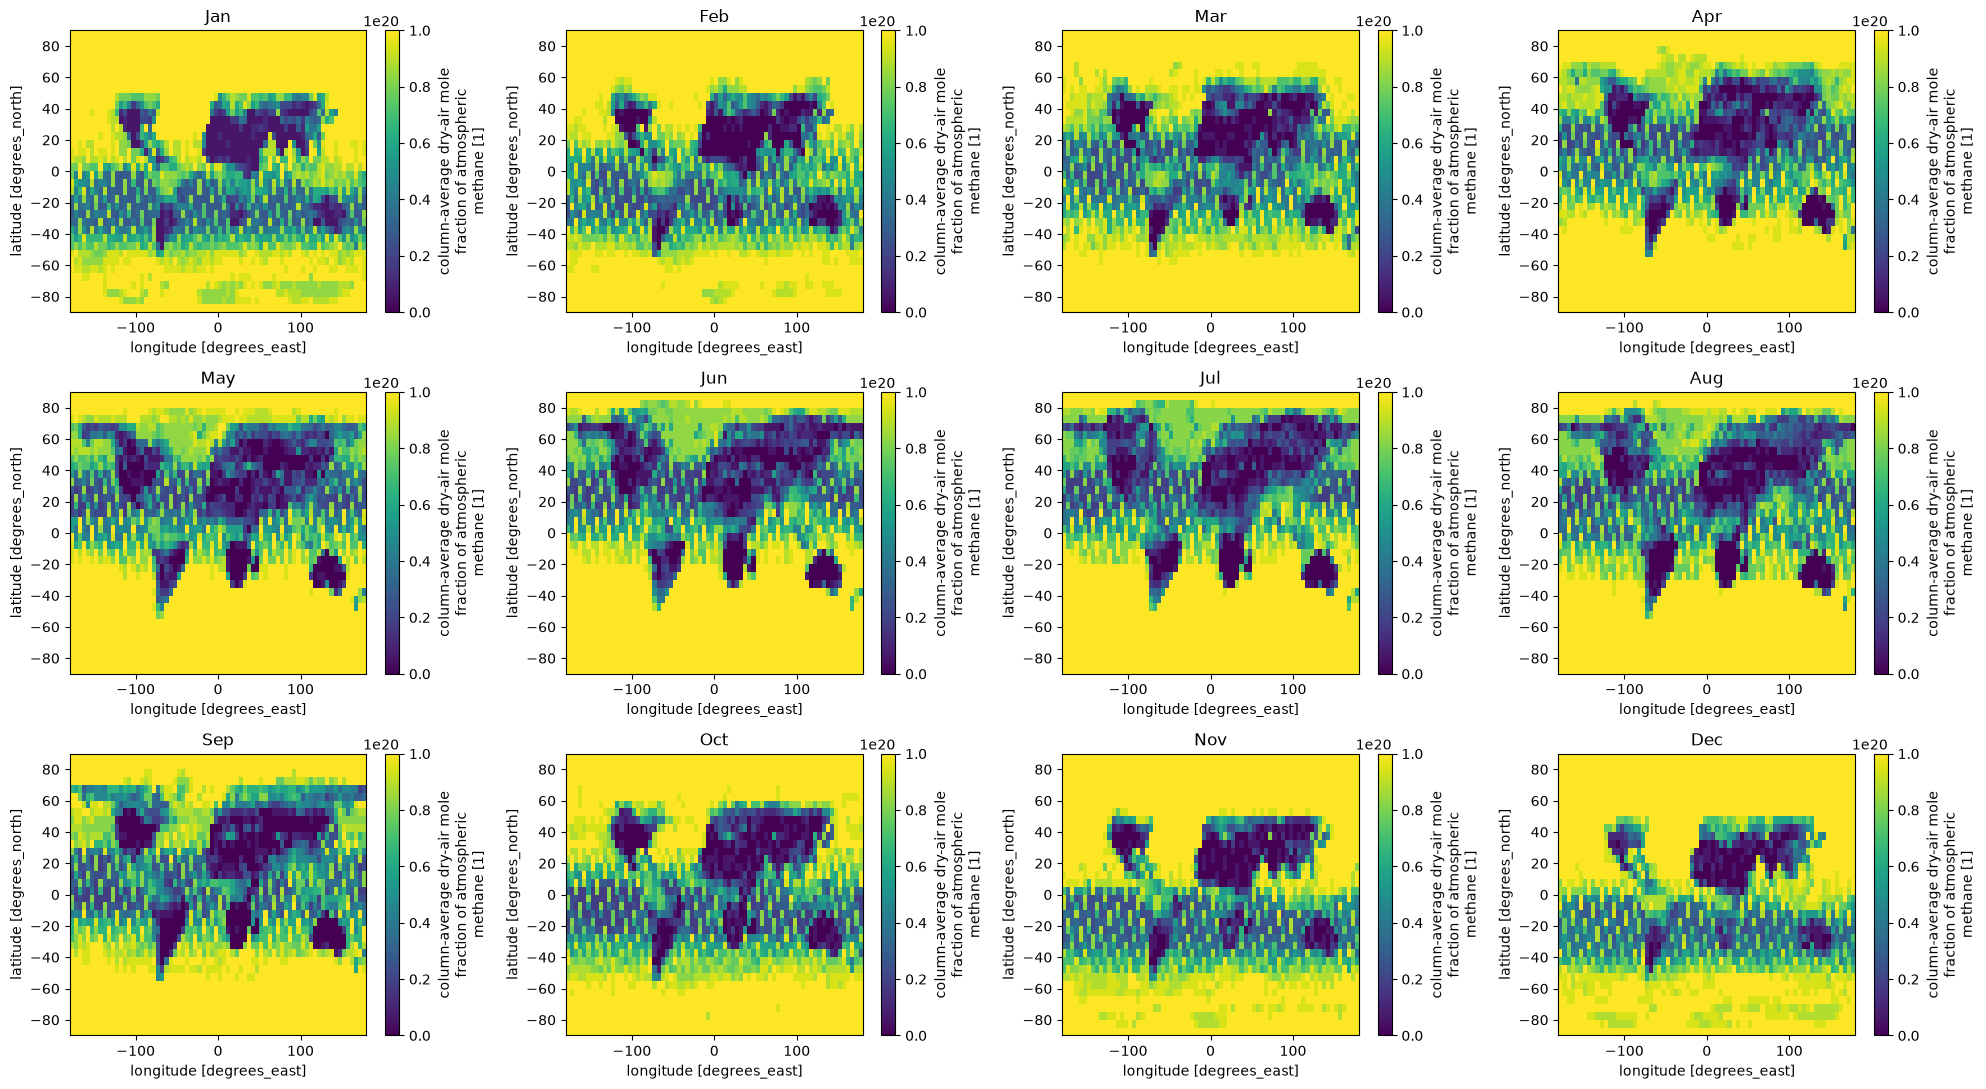

In [25]:
#1.1
xch4 = CH4["xch4"]#把xch4单独提出
CH4_monthly = xch4.groupby("time.month").mean("time")#对数据集按月分组，只在时间这一条维度上对数据集里的数据求平均。此时得到的CH4_monthly为经纬*时间的三维结构
month=["Jan", "Feb", "Mar", "Apr", "May", "Jun","Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(3, 4, figsize=(20, 11))
axes = axes.flatten()

vmin = float(np.nanmin(CH4_monthly.values))#控制十二个图的用色
vmax = float(np.nanmax(CH4_monthly.values))

for i in range(1,13):
    j = CH4_monthly.sel(month=int(i))#j此时为二维网格，可以用.pcolormesh画
    plt.subplot(3,4,int(i))
    j.plot.pcolormesh(x="lon", y="lat",vmin=vmin, vmax=vmax,cmap="viridis",shading="auto")
    plt.title(month[i-1])

plt.tight_layout()
plt.show()

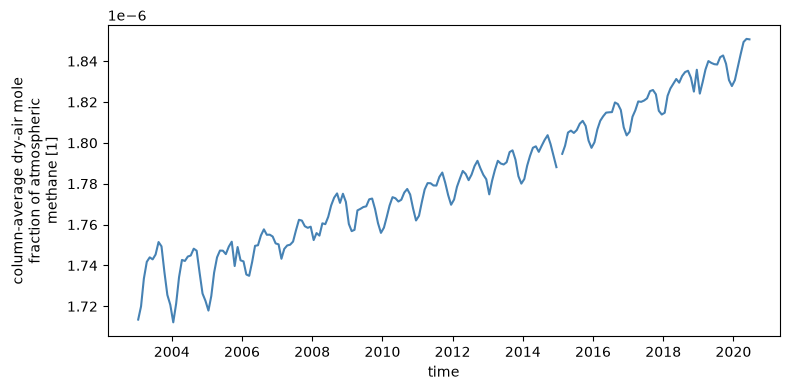

In [26]:
#1.2
valid_CH4 = CH4["xch4_nobs"] > 0       #排除无效值
xch4_masked = xch4.where(valid_CH4)

weights = np.cos(np.deg2rad(xch4_masked["lat"]))#因为纬度带来的面积差异，故而应用面积加权
CH4_global_corrected = xch4_masked.weighted(weights).mean(dim=["lat", "lon"])

fig, (ax1) = plt.subplots(figsize=(8, 4), sharex=True)
CH4_global_corrected.plot(ax=ax1, color="steelblue")
plt.tight_layout()
plt.show()

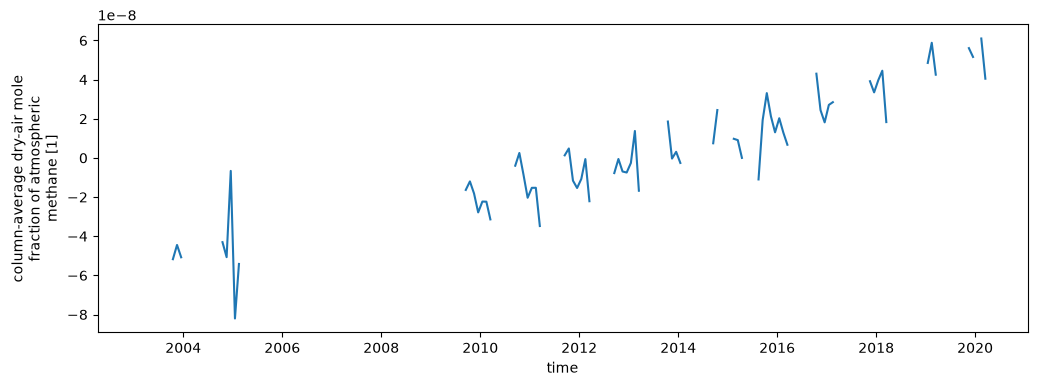

In [14]:
#1.3
xch4_1_3 = CH4["xch4"].sel(lat=-15, lon=-150, method="nearest")#选中特定位置的数据
nobs_1_3 = CH4["xch4_nobs"].sel(lat=-15, lon=-150, method="nearest")#去除无效值
xch4_1_3 = xch4_1_3.where(nobs_1_3 > 0)

clim_1_3 = xch4_1_3.groupby("time.month").mean("time")
xch4_deseason = xch4_1_3.groupby("time.month") - clim_pt

xch4_deseason.plot(figsize=(12, 4))
plt.show()

In [16]:
#2
T = xr.open_dataset('NOAA_NCDC_ERSST_v3b_SST.nc')
print(T)
T.head()

<xarray.Dataset> Size: 44MB
Dimensions:  (time: 684, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 44MB ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...


<xarray.Dataset> Size: 580B
Dimensions:  (time: 5, lat: 5, lon: 5)
Coordinates:
  * time     (time) datetime64[ns] 40B 1960-01-15 1960-02-15 ... 1960-05-15
  * lat      (lat) float32 20B -88.0 -86.0 -84.0 -82.0 -80.0
  * lon      (lon) float32 20B 0.0 2.0 4.0 6.0 8.0
Data variables:
    sst      (time, lat, lon) float32 500B ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...

('time', 'lat', 'lon') (684, 5, 26)


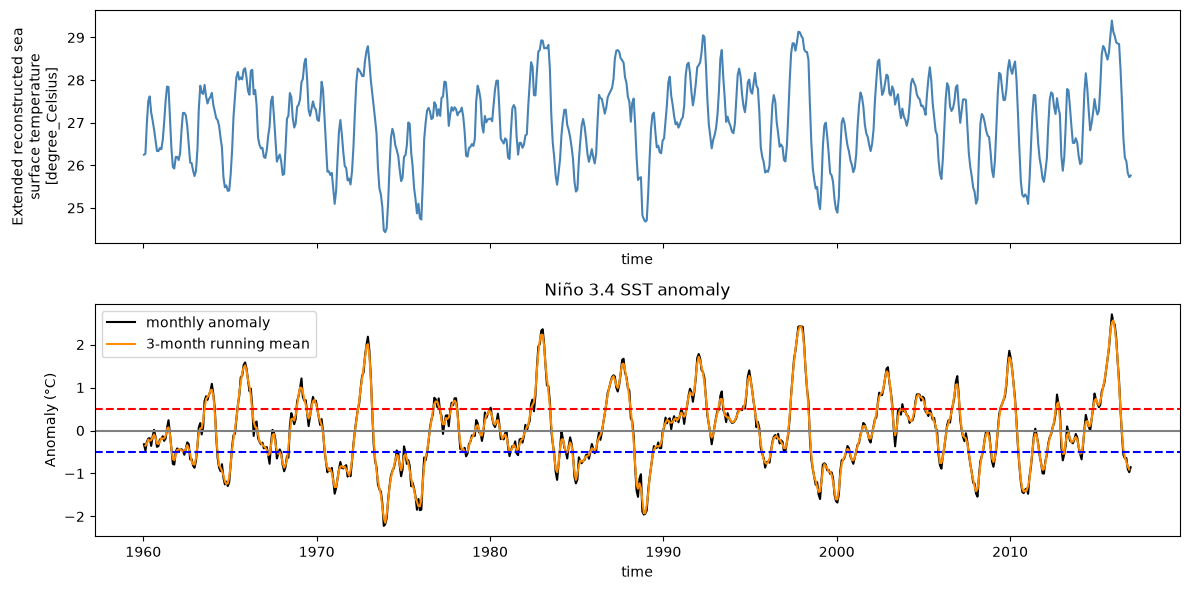

In [25]:
#2.1
sst2_1 = T["sst"].sel(lat=slice(-5, 5), lon=slice(190, 240))#选中范围
#print(sst2_1.dims, sst2_1.shape)

weights = np.cos(np.deg2rad(sst2_1["lat"]))#按纬度加权平均
sst2_1_w = sst2_1.weighted(weights).mean(dim=["lat", "lon"])

sst_clim = sst2_1_w.groupby("time.month").mean("time")#求平均

sst_anom = sst2_1_w.groupby("time.month") - sst_clim#减去平均得异常波动值

sst_anom_3m = sst_anom.rolling(time=3, center=True).mean()#再求三个月的滑动平均

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)#最后画图

sst2_1_w.plot(ax=axes[0], color="steelblue")

sst_anom.plot(ax=axes[1], color="black",label="monthly anomaly")
sst_anom_3m.plot(ax=axes[1], color="darkorange",label="3-month running mean")
axes[1].axhline(0, color="gray")
axes[1].axhline( 0.5, color="red",ls="--")
axes[1].axhline(-0.5, color="blue",ls="--")
axes[1].set_title("Niño 3.4 SST anomaly")
axes[1].set_ylabel("Anomaly (°C)")
axes[1].legend()

plt.tight_layout()
plt.show()

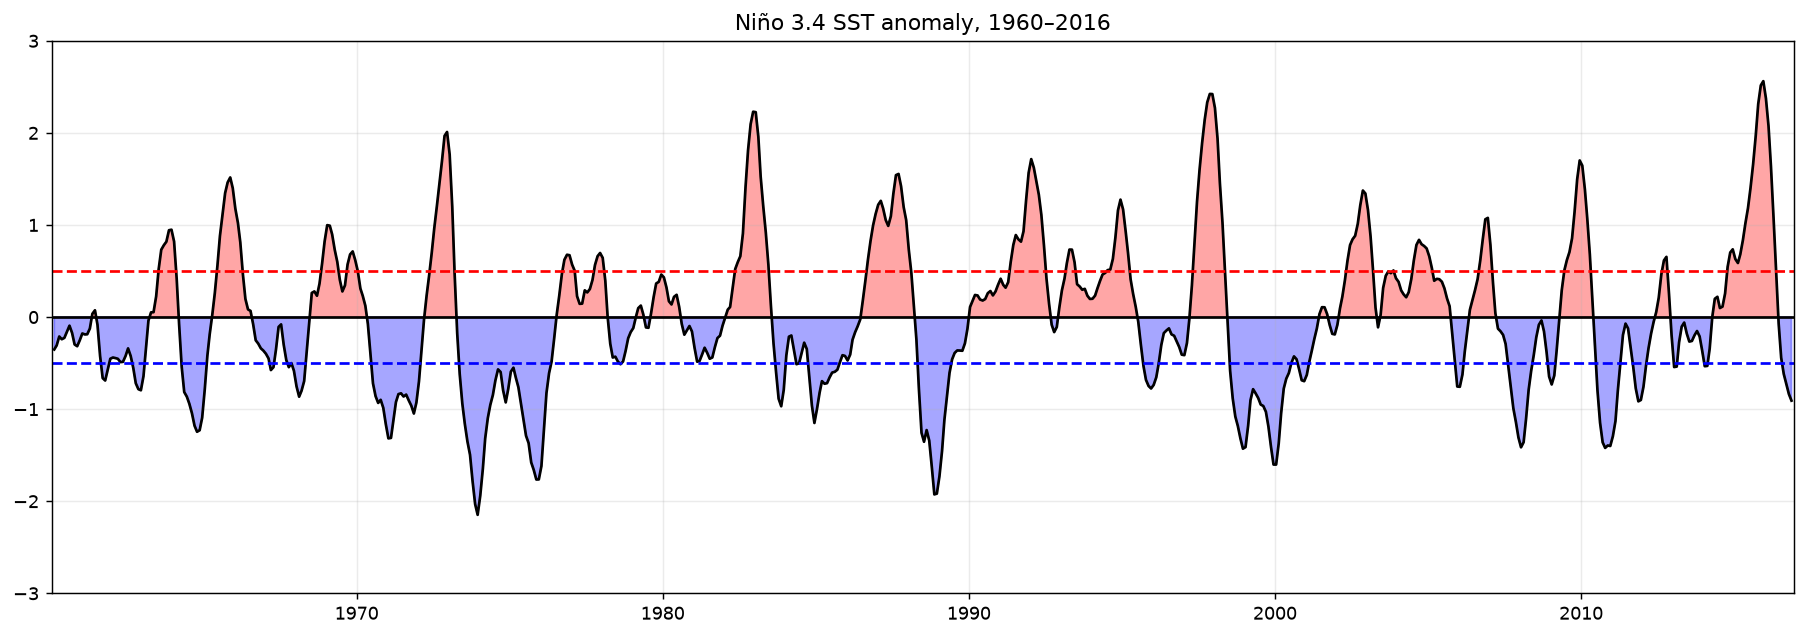

In [28]:
#2.2
fig, ax = plt.subplots(figsize=(14, 5), dpi=130)

time = sst_anom["time"].values
anom = sst_anom.values
anom_3m = sst_anom_3m.values

ax.fill_between(time, 0, anom_3m, where=(anom_3m >= 0),color="red",  alpha=0.35, interpolate=True)#分区域填色
ax.fill_between(time, 0, anom_3m, where=(anom_3m < 0), color="blue", alpha=0.35, interpolate=True)

ax.plot(time, anom_3m, color="black")

ax.axhline(0,color="black")#三根辅助线
ax.axhline(0.5, color="red", ls="--")
ax.axhline(-0.5, color="blue",ls="--")

ax.set_xlim(time[0], time[-1])
ax.set_ylim(-3, 3)
ax.set_title("Niño 3.4 SST anomaly, 1960–2016")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [31]:
#3
ds = xr.open_dataset('NOAA_NCDC_ERSST_v3b_SST.nc')
print(ds)
print(ds.data_vars)

<xarray.Dataset> Size: 3GB
Dimensions:     (lat: 16200, lon: 43080)
Coordinates:
  * lat         (lat) float64 130kB -60.05 -60.04 -60.03 ... 74.93 74.94 74.95
  * lon         (lon) float64 345kB -179.5 -179.5 -179.5 ... 179.4 179.4 179.4
Data variables:
    crs         |S1 1B ...
    SurfaceNO2  (lat, lon) float32 3GB ...
Attributes: (12/24)
    GDAL_AREA_OR_POINT:       Area
    Conventions:              CF-1.5
    GDAL:                     GDAL 3.1.2, released 2020/07/07
    title:                    Nitrogen Dioxide Surface-Level Annual Average C...
    NCO:                      netCDF Operators version 4.9.3 (Homepage = http...
    institution:              George Washington University, Department of Env...
    ...                       ...
    SouthBoundingCoordinate:  -60.0
    NorthBoundingCoordinate:  75.0
    WestBoundingCoordinate:   -180.0
    EastBoundingCoordinate:   180.0
    history:                  2023-02-04 12:28:24 - original file generated u...
    VersionID:     

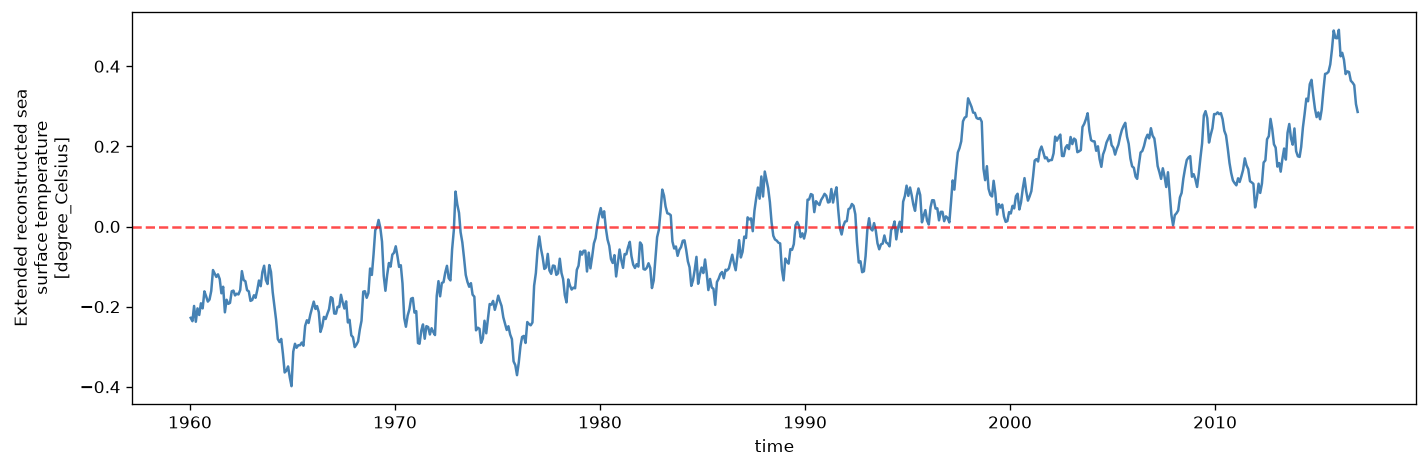

In [12]:
#3.1
var_ds = ds["sst"] 

weights = np.cos(np.deg2rad(var_ds["lat"]))#按纬度加权平均
var_ds_w = var_ds.weighted(weights).mean(dim=["lat", "lon"])

var_clim = var_ds_w.groupby("time.month").mean("time")#求平均
var_anom = var_ds_w.groupby("time.month") - var_clim#减去平均得异常波动值

fig, ax = plt.subplots(figsize=(12, 4), dpi=120)#画图
var_anom.plot(ax=ax, color="steelblue")
ax.axhline(0, color="red", linestyle="--", alpha=0.7) 
plt.tight_layout()
plt.show()

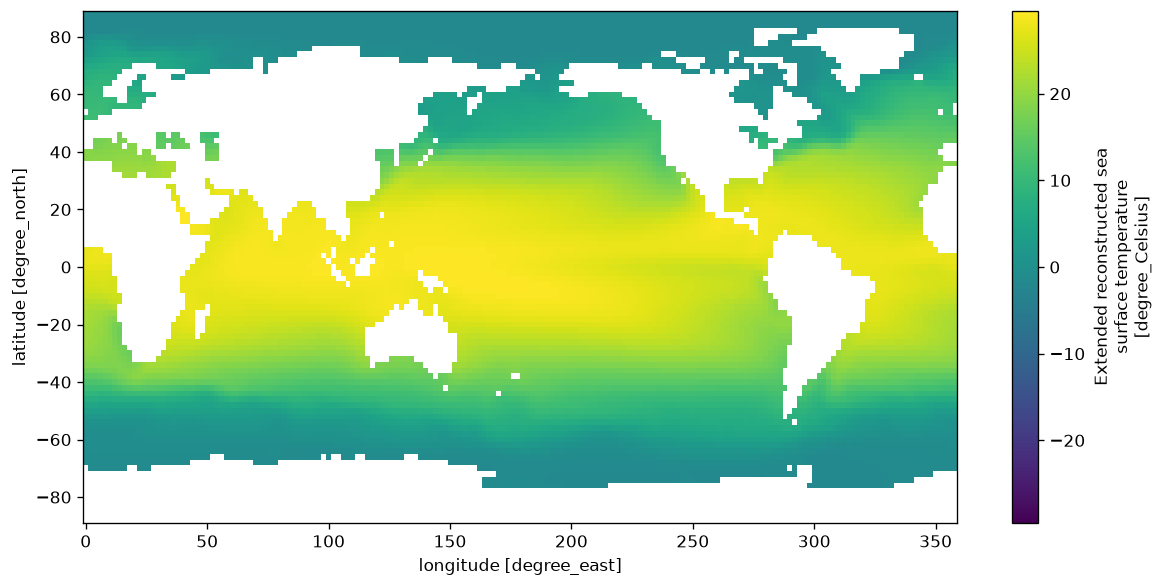

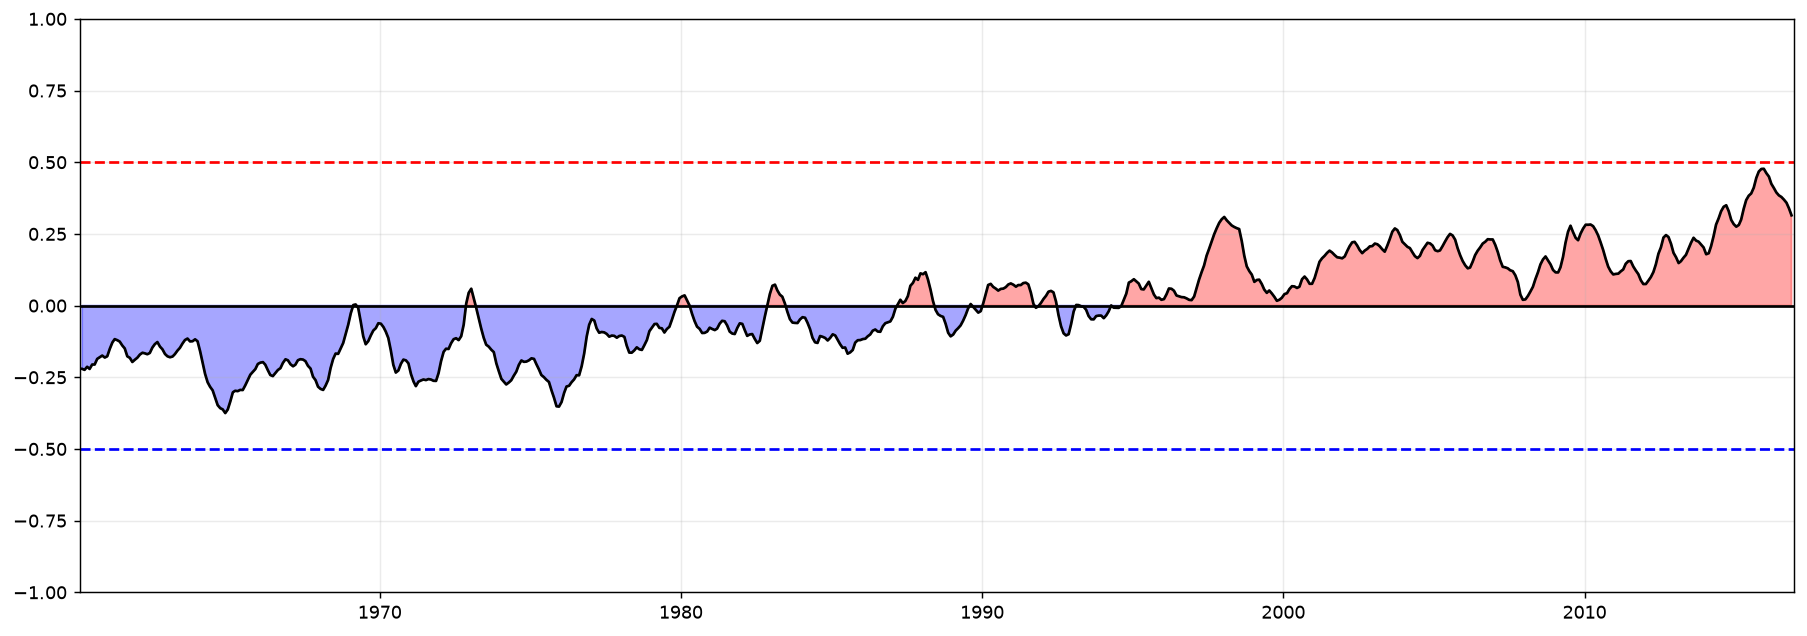

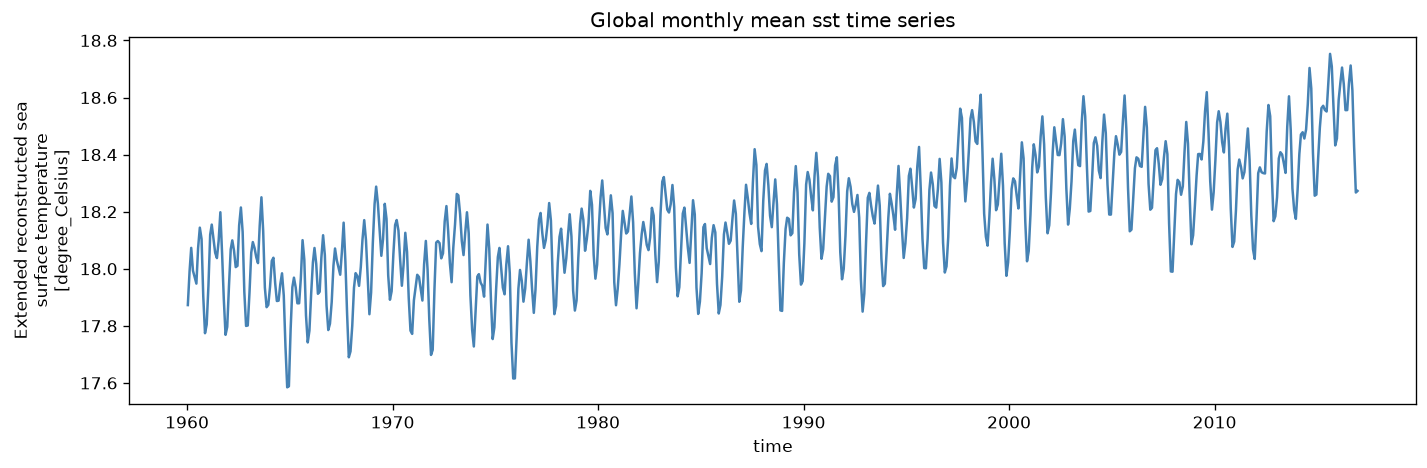

In [18]:
#3.2
#图一：全球二维 pcolormesh
fig, ax1 = plt.subplots(figsize=(10, 5), dpi=120)
var_ds.mean("time").plot.pcolormesh(x="lon", y="lat", cmap="viridis", shading="auto", ax=ax1)
plt.tight_layout()
plt.show()

#图二：类似#2.2
var_anom_3m = var_anom.rolling(time=3, center=True).mean()
fig, ax2 = plt.subplots(figsize=(14, 5), dpi=130)

var_time = var_anom["time"].values
var_anom_3m_values = var_anom_3m.values

ax2.fill_between(var_time, 0, var_anom_3m_values,where=(var_anom_3m_values >= 0),color="red", alpha=0.35, interpolate=True)
ax2.fill_between(var_time, 0, var_anom_3m_values,where=(var_anom_3m_values < 0),color="blue", alpha=0.35, interpolate=True)
ax2.plot(var_time, var_anom_3m_values, color="black")

ax2.axhline(0, color="black")
ax2.axhline(0.5, color="red", ls="--")
ax2.axhline(-0.5, color="blue", ls="--")

ax2.set_xlim(var_time[0], var_time[-1])
ax2.set_ylim(-1, 1)
ax2.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 图三：全球加权平均值的月平均时间序列图
fig, ax3 = plt.subplots(figsize=(12, 4), dpi=120)
var_ds_w.plot(ax=ax3, color="steelblue")
ax3.set_title("Global monthly mean sst time series")
plt.tight_layout()
plt.show()

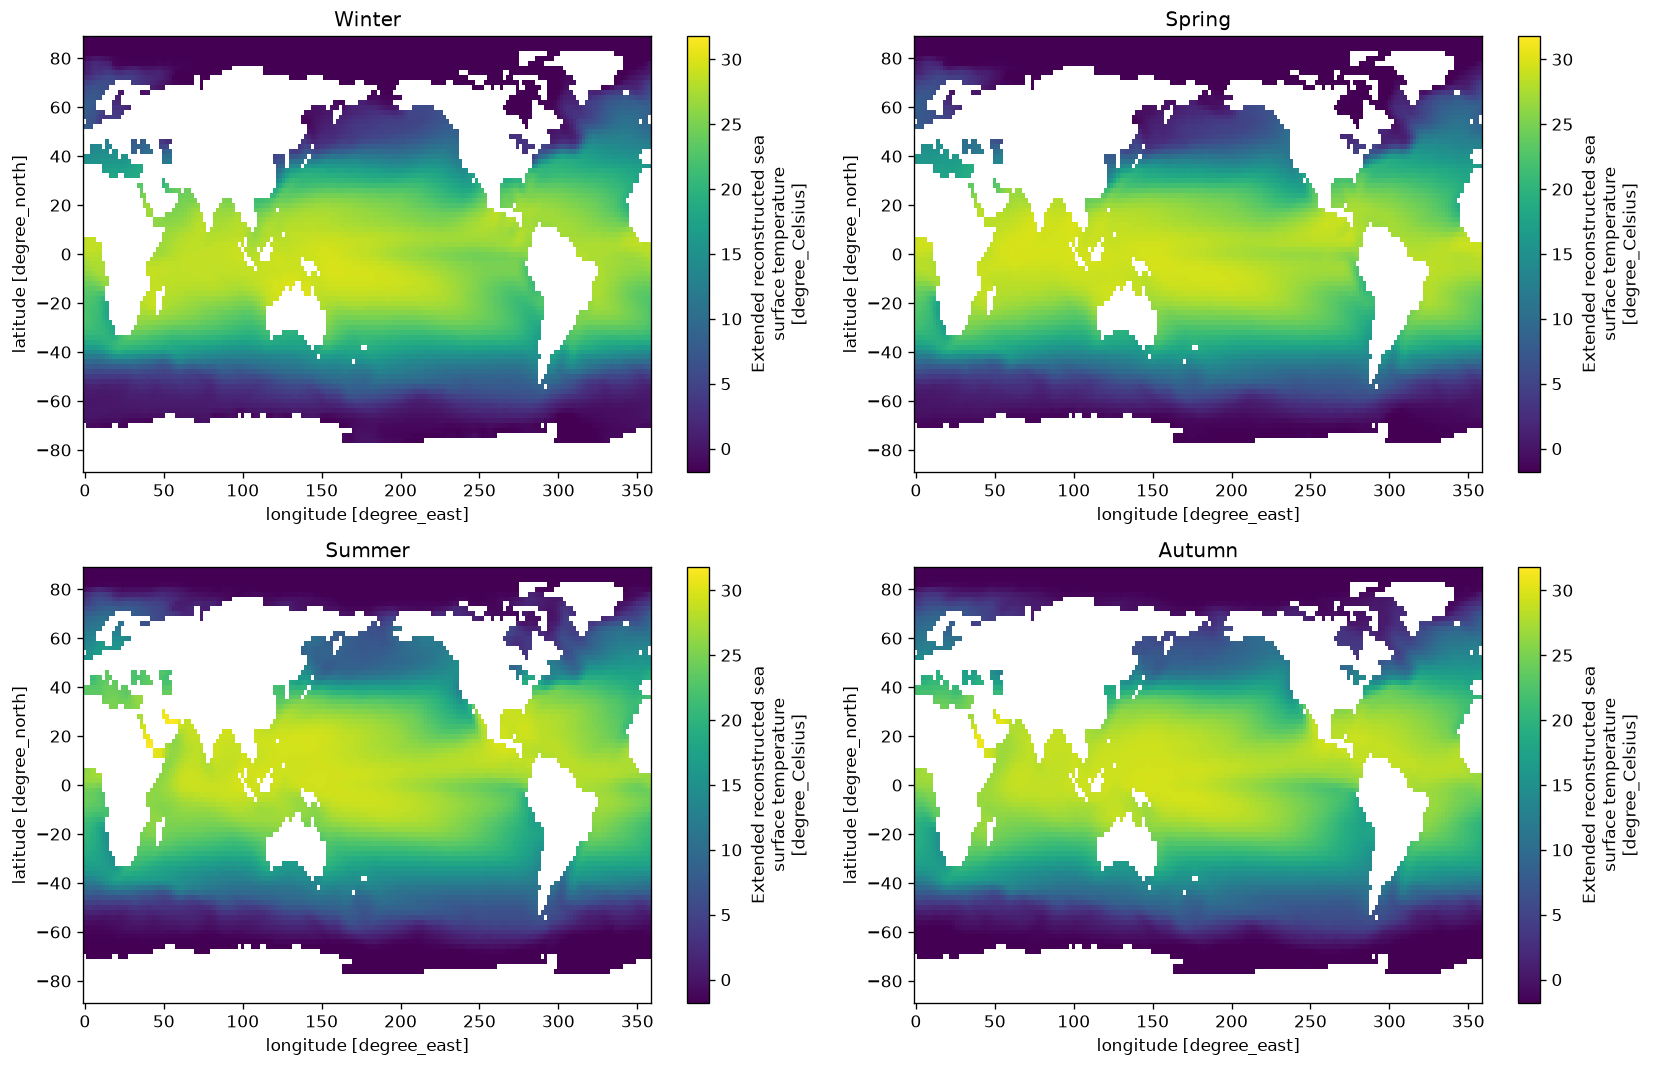

In [19]:
#图四：四季对比
season_order = ["DJF", "MAM", "JJA", "SON"]
season_cn = {"DJF": "Winter", "MAM": "Spring", "JJA": "Summer", "SON": "Autumn"}
var_season = var_ds.groupby("time.season").mean("time")

fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=120)
axes = axes.flatten()
vmin = float(np.nanmin(var_season.values))
vmax = float(np.nanmax(var_season.values))
for i, s in enumerate(season_order):
    var_season.sel(season=s).plot.pcolormesh(
        x="lon", y="lat", vmin=vmin, vmax=vmax,
        cmap="viridis", shading="auto", ax=axes[i]
    )
    axes[i].set_title(season_cn[s])
plt.tight_layout()
plt.show()

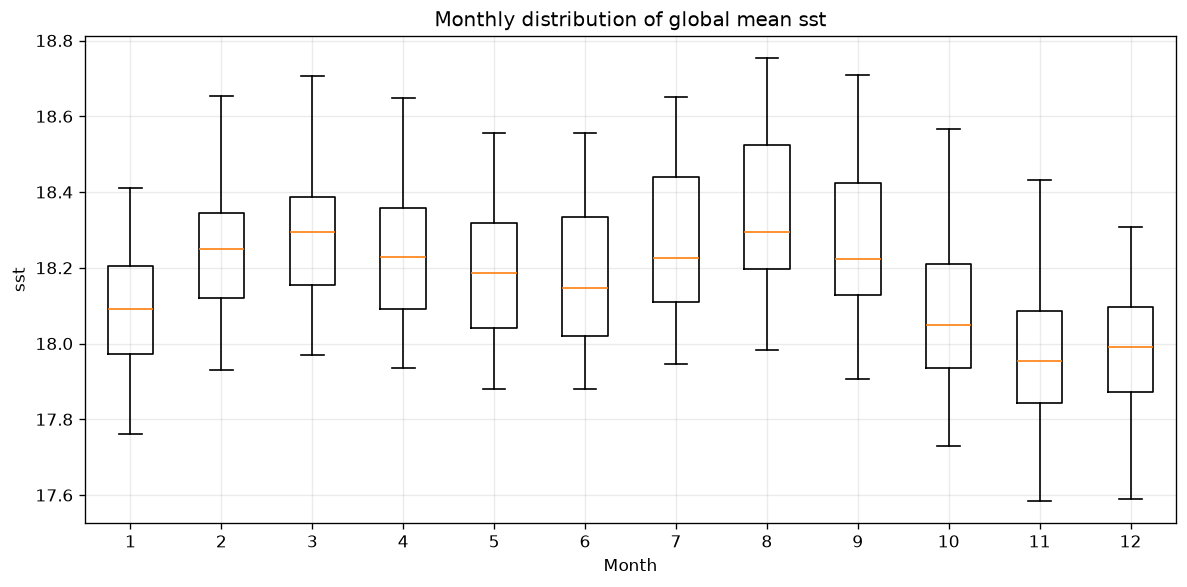

In [28]:
#图五：箱线图
fig, ax4 = plt.subplots(figsize=(10, 5), dpi=120)
ax4.boxplot(var_monthly_groups, showfliers=False)
ax4.set_title("Monthly distribution of global mean sst")
ax4.set_xlabel("Month")
ax4.set_ylabel("sst")
ax4.grid(alpha=0.25)
plt.tight_layout()
plt.show()